# Health&Life Analytics — Análise Completa de Café, Cafeína e Saúde

**Empresa fictícia:** Health&Life Analytics  
**Objetivo:** analisar relações entre consumo de café, cafeína, sono, estresse e indicadores de saúde, e construir modelos preditivos para `Sleep_Quality`.

> Observação metodológica: a base é **sintética**. Correlações e desempenho preditivo **não** devem ser interpretados como prova de causalidade clínica.


## 1. Configuração do ambiente

Carrega bibliotecas e define caminhos relativos à raiz do projeto.


In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110

# Garante importação dos módulos locais (src/)
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DATA_RAW, DATA_PROCESSED, RESULTS_DIR, GRAFICOS_DIR, RANDOM_STATE
from src.preprocessamento import carregar_dados_brutos, tratar_dados, exportar_processado
from src.analise_exploratoria import (
    resumo_estrutura,
    detectar_outliers_iqr,
    estatisticas_descritivas,
    exportar_estatisticas,
)
from src.visualizacoes import gerar_todas_visualizacoes
from src.machine_learning import treinar_e_comparar, preparar_xy

print("Raiz do projeto:", PROJECT_ROOT)
print("Dataset bruto:", DATA_RAW)
print("Existe?", DATA_RAW.exists())


Raiz do projeto: C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics
Dataset bruto: C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\data\raw\synthetic_coffee_health_10000.csv
Existe? True


## 2. Etapa 1 — Análise Exploratória de Dados (EDA)

### 2.1 Carregamento e inspeção inicial


In [2]:
df_raw = carregar_dados_brutos()

print("Shape:", df_raw.shape)
print("\nCinco primeiros registros:")
display(df_raw.head())
print("Cinco últimos registros:")
display(df_raw.tail())


Shape: (10000, 16)

Cinco primeiros registros:


,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


Cinco últimos registros:


,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
9995,9996,50,Female,Japan,2.1,199.8,6.0,Fair,30.5,50,Medium,10.1,Moderate,Healthcare,0,1
9996,9997,18,Female,UK,3.4,319.2,5.8,Fair,19.1,71,Medium,11.6,Mild,Service,0,0
9997,9998,26,Male,China,1.6,153.4,7.1,Good,25.1,66,Low,13.7,NaN,Student,1,1
9998,9999,40,Female,Finland,3.4,327.1,7.0,Good,19.3,80,Low,0.1,NaN,Student,0,0
9999,10000,42,Female,Brazil,2.9,277.5,6.4,Good,28.1,72,Low,9.8,NaN,Student,1,0


In [3]:
print("Colunas e tipos:")
print(df_raw.dtypes)
print("\nValores ausentes:")
print(df_raw.isna().sum())
print("\nDuplicados:", df_raw.duplicated().sum())


Colunas e tipos:
ID                           int64
Age                          int64
Gender                         str
Country                        str
Coffee_Intake              float64
Caffeine_mg                float64
Sleep_Hours                float64
Sleep_Quality                  str
BMI                        float64
Heart_Rate                   int64
Stress_Level                   str
Physical_Activity_Hours    float64
Health_Issues                  str
Occupation                     str
Smoking                      int64
Alcohol_Consumption          int64
dtype: object

Valores ausentes:
ID                            0
Age                           0
Gender                        0
Country                       0
Coffee_Intake                 0
Caffeine_mg                   0
Sleep_Hours                   0
Sleep_Quality                 0
BMI                           0
Heart_Rate                    0
Stress_Level                  0
Physical_Activity_Hours       0
Health

### 2.2 Dicionário resumido das variáveis

| Coluna | Tipo esperado | Significado |
|---|---|---|
| ID | identificador | Chave única do registro |
| Age | numérico | Idade (anos) |
| Gender | categórico | Gênero |
| Country | categórico | País |
| Coffee_Intake | numérico | Consumo de café (xícaras/unidades) |
| Caffeine_mg | numérico | Cafeína estimada (mg) |
| Sleep_Hours | numérico | Horas de sono |
| Sleep_Quality | categórico | Qualidade do sono (alvo) |
| BMI | numérico | Índice de Massa Corporal |
| Heart_Rate | numérico | Frequência cardíaca |
| Stress_Level | categórico | Nível de estresse |
| Physical_Activity_Hours | numérico | Horas de atividade física |
| Health_Issues | categórico | Problemas de saúde reportados |
| Occupation | categórico | Ocupação |
| Smoking | numérico/binário | Indicador de tabagismo |
| Alcohol_Consumption | numérico/binário | Indicador de consumo de álcool |


In [4]:
print("Estatísticas descritivas (numéricas):")
display(df_raw.describe().T)

print("\nDistribuições categóricas principais:")
for col in ["Gender", "Sleep_Quality", "Stress_Level", "Health_Issues", "Occupation"]:
    print(f"\n--- {col} ---")
    print(df_raw[col].value_counts())


Estatísticas descritivas (numéricas):


,count,mean,std,min,25%,50%,75%,max
ID,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.250,10000.0
Age,10000.0,34.94910,11.160939,18.0,26.00,34.0,43.000,80.0
Coffee_Intake,10000.0,2.50923,1.450248,0.0,1.50,2.5,3.500,8.2
Caffeine_mg,10000.0,238.41101,137.748815,0.0,138.75,235.4,332.025,780.3
Sleep_Hours,10000.0,6.63622,1.222055,3.0,5.80,6.6,7.500,10.0
BMI,10000.0,23.98686,3.906411,15.0,21.30,24.0,26.600,38.2
Heart_Rate,10000.0,70.61780,9.822951,50.0,64.00,71.0,77.000,109.0
Physical_Activity_Hours,10000.0,7.48704,4.315180,0.0,3.70,7.5,11.200,15.0
Smoking,10000.0,0.20040,0.400320,0.0,0.00,0.0,0.000,1.0
Alcohol_Consumption,10000.0,0.30070,0.458585,0.0,0.00,0.0,1.000,1.0



Distribuições categóricas principais:

--- Gender ---
Gender
Female    5001
Male      4773
Other      226
Name: count, dtype: int64

--- Sleep_Quality ---
Sleep_Quality
Good         5637
Fair         2050
Excellent    1352
Poor          961
Name: count, dtype: int64

--- Stress_Level ---
Stress_Level
Low       6989
Medium    2050
High       961
Name: count, dtype: int64

--- Health_Issues ---
Health_Issues
Mild        3579
Moderate     463
Severe        17
Name: count, dtype: int64

--- Occupation ---
Occupation
Office        2073
Other         2038
Student       1968
Healthcare    1964
Service       1957
Name: count, dtype: int64


### 2.3 Limpeza e tratamento

Alterações aplicadas:
1. Remoção de duplicatas (se existirem), para evitar enviesar frequências e modelos.
2. Imputação de ausentes numéricos pela mediana e categóricos pela moda.
3. Criação de variáveis derivadas **sem uso do alvo**:
   - `Caffeine_per_Cup`: intensidade de cafeína por unidade de café.
   - `Age_Group`: faixa etária para análises comparativas.
   - `Risk_Habits`: combinação de tabaco e álcool.


In [5]:
df = tratar_dados(df_raw)
exportar_processado(df)

estrutura = resumo_estrutura(df)
print(estrutura)
print("\nOutliers (método IQR):")
display(detectar_outliers_iqr(df))

stats = exportar_estatisticas(df)
display(stats.head(20))
print("Dataset processado salvo em:", DATA_PROCESSED)


{'n_linhas': 10000, 'n_colunas': 19, 'colunas': ['ID', 'Age', 'Gender', 'Country', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'Sleep_Quality', 'BMI', 'Heart_Rate', 'Stress_Level', 'Physical_Activity_Hours', 'Health_Issues', 'Occupation', 'Smoking', 'Alcohol_Consumption', 'Caffeine_per_Cup', 'Age_Group', 'Risk_Habits'], 'tipos': {'ID': 'int64', 'Age': 'int64', 'Gender': 'str', 'Country': 'str', 'Coffee_Intake': 'float64', 'Caffeine_mg': 'float64', 'Sleep_Hours': 'float64', 'Sleep_Quality': 'str', 'BMI': 'float64', 'Heart_Rate': 'int64', 'Stress_Level': 'str', 'Physical_Activity_Hours': 'float64', 'Health_Issues': 'str', 'Occupation': 'str', 'Smoking': 'int64', 'Alcohol_Consumption': 'int64', 'Caffeine_per_Cup': 'float64', 'Age_Group': 'str', 'Risk_Habits': 'int64'}, 'ausentes': {'ID': 0, 'Age': 0, 'Gender': 0, 'Country': 0, 'Coffee_Intake': 0, 'Caffeine_mg': 0, 'Sleep_Hours': 0, 'Sleep_Quality': 0, 'BMI': 0, 'Heart_Rate': 0, 'Stress_Level': 0, 'Physical_Activity_Hours': 0, 'Health_I

,variavel,q1,q3,iqr,limite_inferior,limite_superior,n_outliers,pct_outliers
0,Age,26.00,43.000,17.000,0.5000,68.5000,25,0.25
1,Coffee_Intake,1.50,3.500,2.000,-1.5000,6.5000,39,0.39
2,Caffeine_mg,138.75,332.025,193.275,-151.1625,621.9375,39,0.39
3,Sleep_Hours,5.80,7.500,1.700,3.2500,10.0500,26,0.26
4,BMI,21.30,26.600,5.300,13.3500,34.5500,40,0.40
5,Heart_Rate,64.00,77.000,13.000,44.5000,96.5000,50,0.50
6,Physical_Activity_Hours,3.70,11.200,7.500,-7.5500,22.4500,0,0.00
7,Smoking,0.00,0.000,0.000,0.0000,0.0000,2004,20.04
8,Alcohol_Consumption,0.00,1.000,1.000,-1.5000,2.5000,0,0.00


,variavel,count,mean,std,min,25%,50%,75%,max,median,missing
0,ID,10000.0,5000.500000,2886.895680,1.0,2500.750000,5000.500000,7500.250000,10000.0,5000.500000,0
1,Age,10000.0,34.949100,11.160939,18.0,26.000000,34.000000,43.000000,80.0,34.000000,0
2,Coffee_Intake,10000.0,2.509230,1.450248,0.0,1.500000,2.500000,3.500000,8.2,2.500000,0
3,Caffeine_mg,10000.0,238.411010,137.748815,0.0,138.750000,235.400000,332.025000,780.3,235.400000,0
4,Sleep_Hours,10000.0,6.636220,1.222055,3.0,5.800000,6.600000,7.500000,10.0,6.600000,0
5,BMI,10000.0,23.986860,3.906411,15.0,21.300000,24.000000,26.600000,38.2,24.000000,0
6,Heart_Rate,10000.0,70.617800,9.822951,50.0,64.000000,71.000000,77.000000,109.0,71.000000,0
7,Physical_Activity_Hours,10000.0,7.487040,4.315180,0.0,3.700000,7.500000,11.200000,15.0,7.500000,0
8,Smoking,10000.0,0.200400,0.400320,0.0,0.000000,0.000000,0.000000,1.0,0.000000,0
9,Alcohol_Consumption,10000.0,0.300700,0.458585,0.0,0.000000,0.000000,1.000000,1.0,0.000000,0


Dataset processado salvo em: C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\data\processed\coffee_health_processed.csv


### 2.4 Distribuições e correlações

Os gráficos abaixo investigam idade, café, cafeína, sono, IMC e frequência cardíaca.


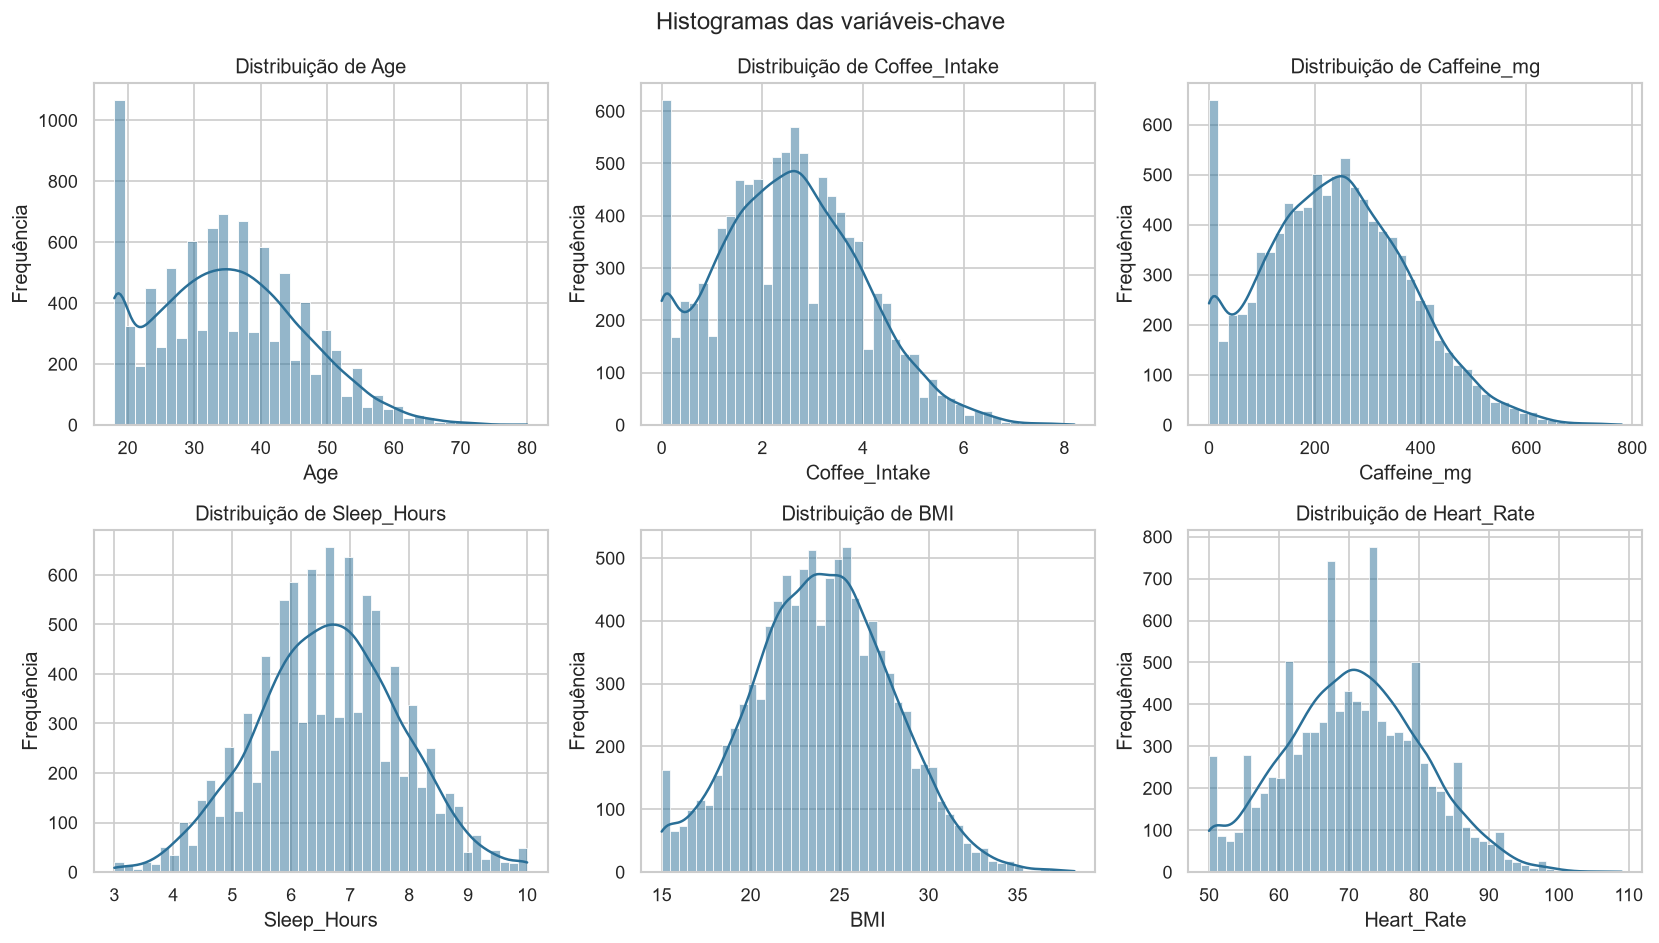

Interpretação: as distribuições ajudam a identificar assimetria, concentração central e possíveis caudas longas (outliers).


In [6]:
cols = ["Age", "Coffee_Intake", "Caffeine_mg", "Sleep_Hours", "BMI", "Heart_Rate"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for ax, col in zip(axes, cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#2a6f97")
    ax.set_title(f"Distribuição de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequência")
fig.suptitle("Histogramas das variáveis-chave")
fig.tight_layout()
plt.show()
print("Interpretação: as distribuições ajudam a identificar assimetria, concentração central e possíveis caudas longas (outliers).")


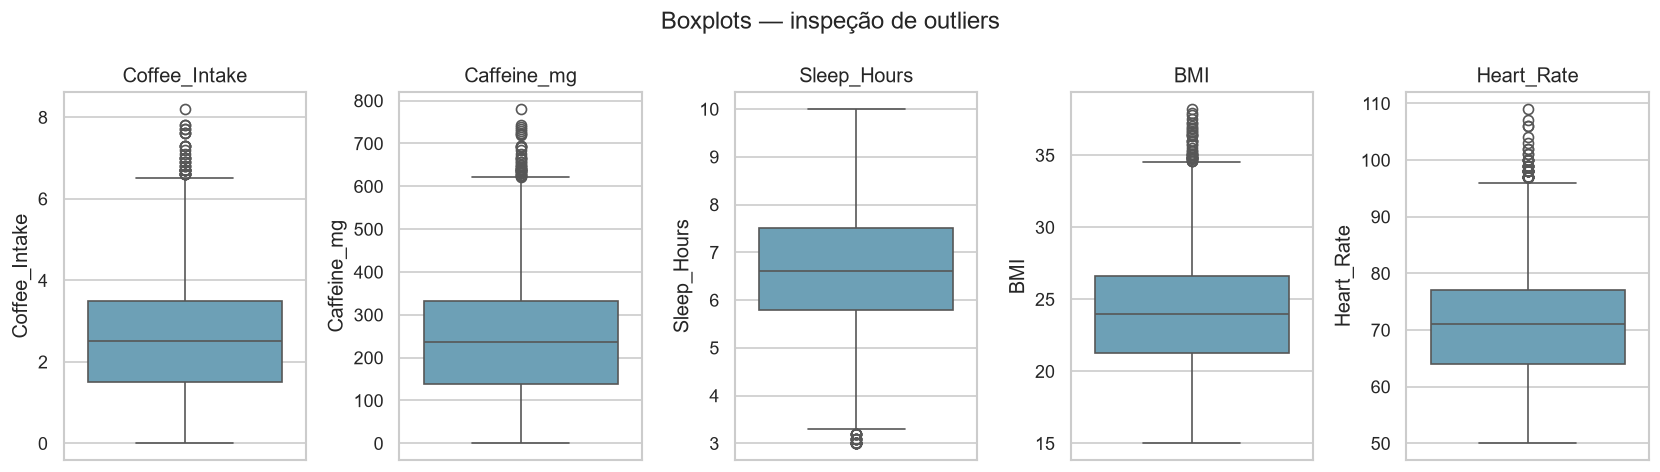

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(14, 4))
for ax, col in zip(axes, ["Coffee_Intake", "Caffeine_mg", "Sleep_Hours", "BMI", "Heart_Rate"]):
    sns.boxplot(y=df[col], ax=ax, color="#61a5c2")
    ax.set_title(col)
fig.suptitle("Boxplots — inspeção de outliers")
fig.tight_layout()
plt.show()


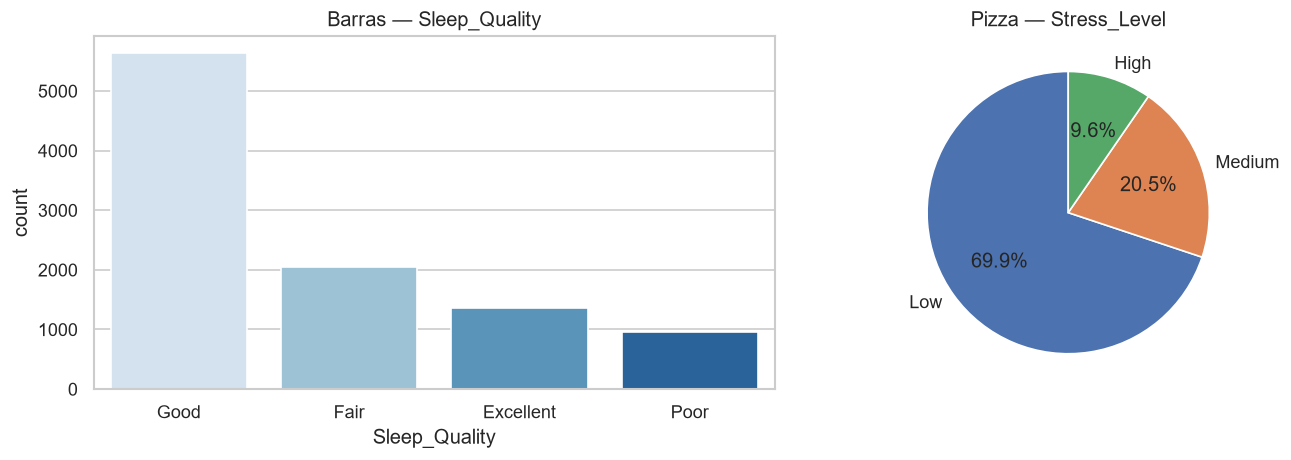

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Sleep_Quality", order=df["Sleep_Quality"].value_counts().index, ax=axes[0], palette="Blues")
axes[0].set_title("Barras — Sleep_Quality")
cont = df["Stress_Level"].value_counts()
axes[1].pie(cont, labels=cont.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Pizza — Stress_Level")
plt.tight_layout()
plt.show()


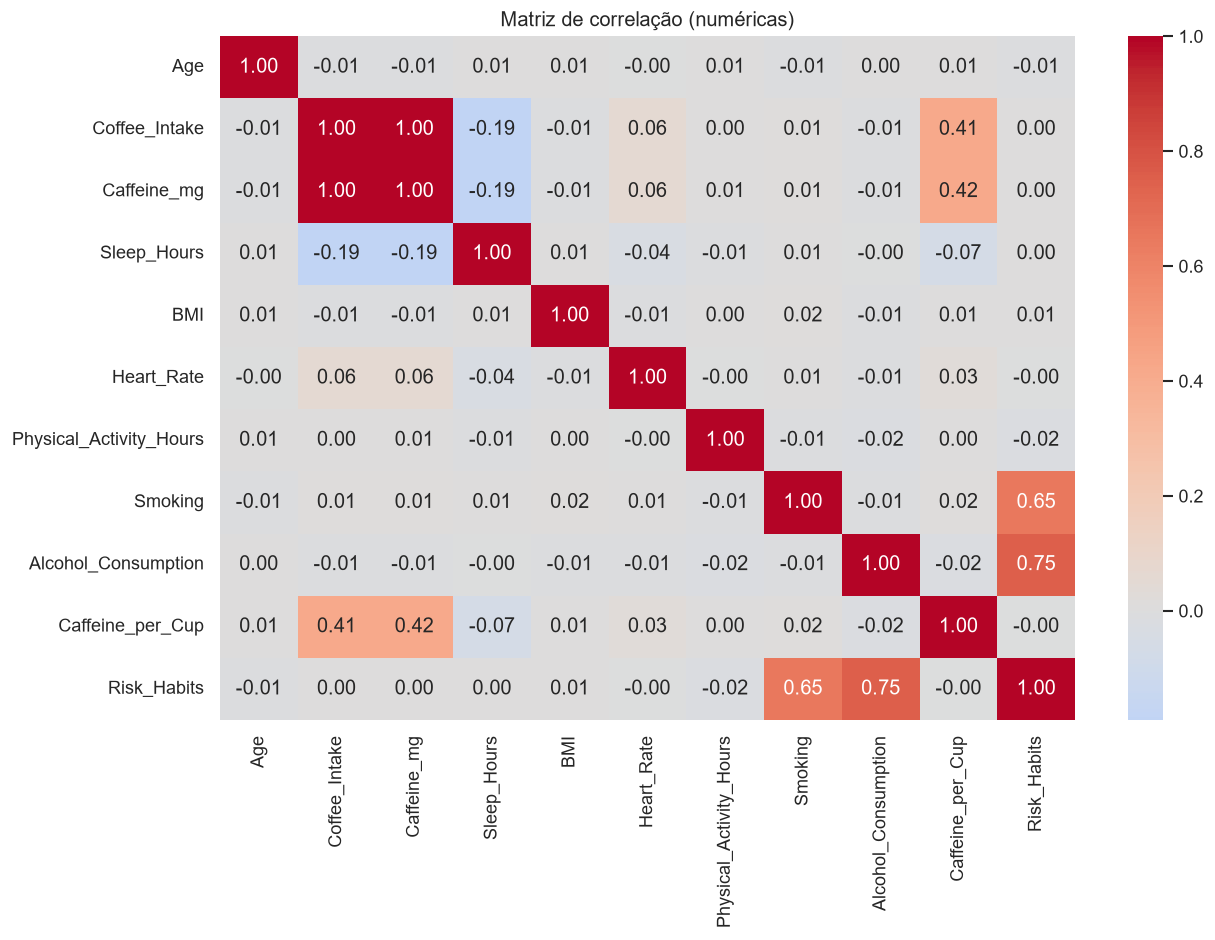

Interpretação: valores próximos de ±1 indicam associação linear forte; valores próximos de 0 sugerem pouca associação linear.
Lembrete: correlação ≠ causalidade.


In [9]:
num = df.select_dtypes(include="number").drop(columns=["ID"], errors="ignore")
corr = num.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação (numéricas)")
plt.tight_layout()
plt.show()
print("Interpretação: valores próximos de ±1 indicam associação linear forte; valores próximos de 0 sugerem pouca associação linear.")
print("Lembrete: correlação ≠ causalidade.")


## 3. Etapa 2 — Visualizações comparativas e insights


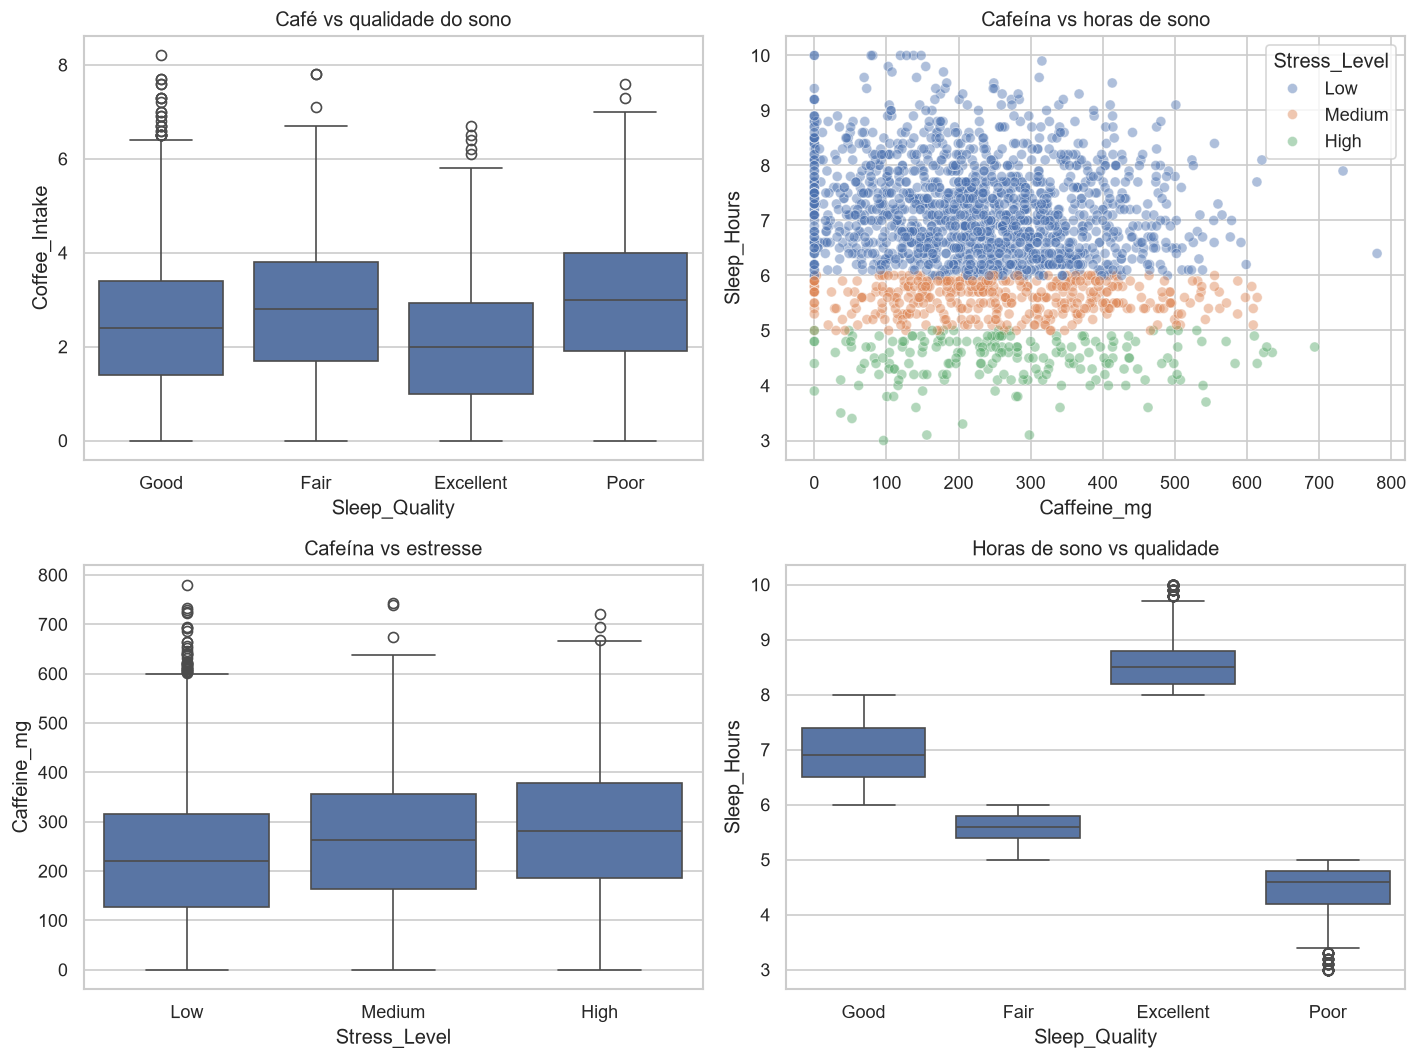

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=df, x="Sleep_Quality", y="Coffee_Intake", ax=axes[0, 0])
axes[0, 0].set_title("Café vs qualidade do sono")

sample = df.sample(n=min(2000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="Caffeine_mg", y="Sleep_Hours", hue="Stress_Level", alpha=0.45, ax=axes[0, 1])
axes[0, 1].set_title("Cafeína vs horas de sono")

sns.boxplot(data=df, x="Stress_Level", y="Caffeine_mg", ax=axes[1, 0])
axes[1, 0].set_title("Cafeína vs estresse")

sns.boxplot(data=df, x="Sleep_Quality", y="Sleep_Hours", ax=axes[1, 1])
axes[1, 1].set_title("Horas de sono vs qualidade")

plt.tight_layout()
plt.show()


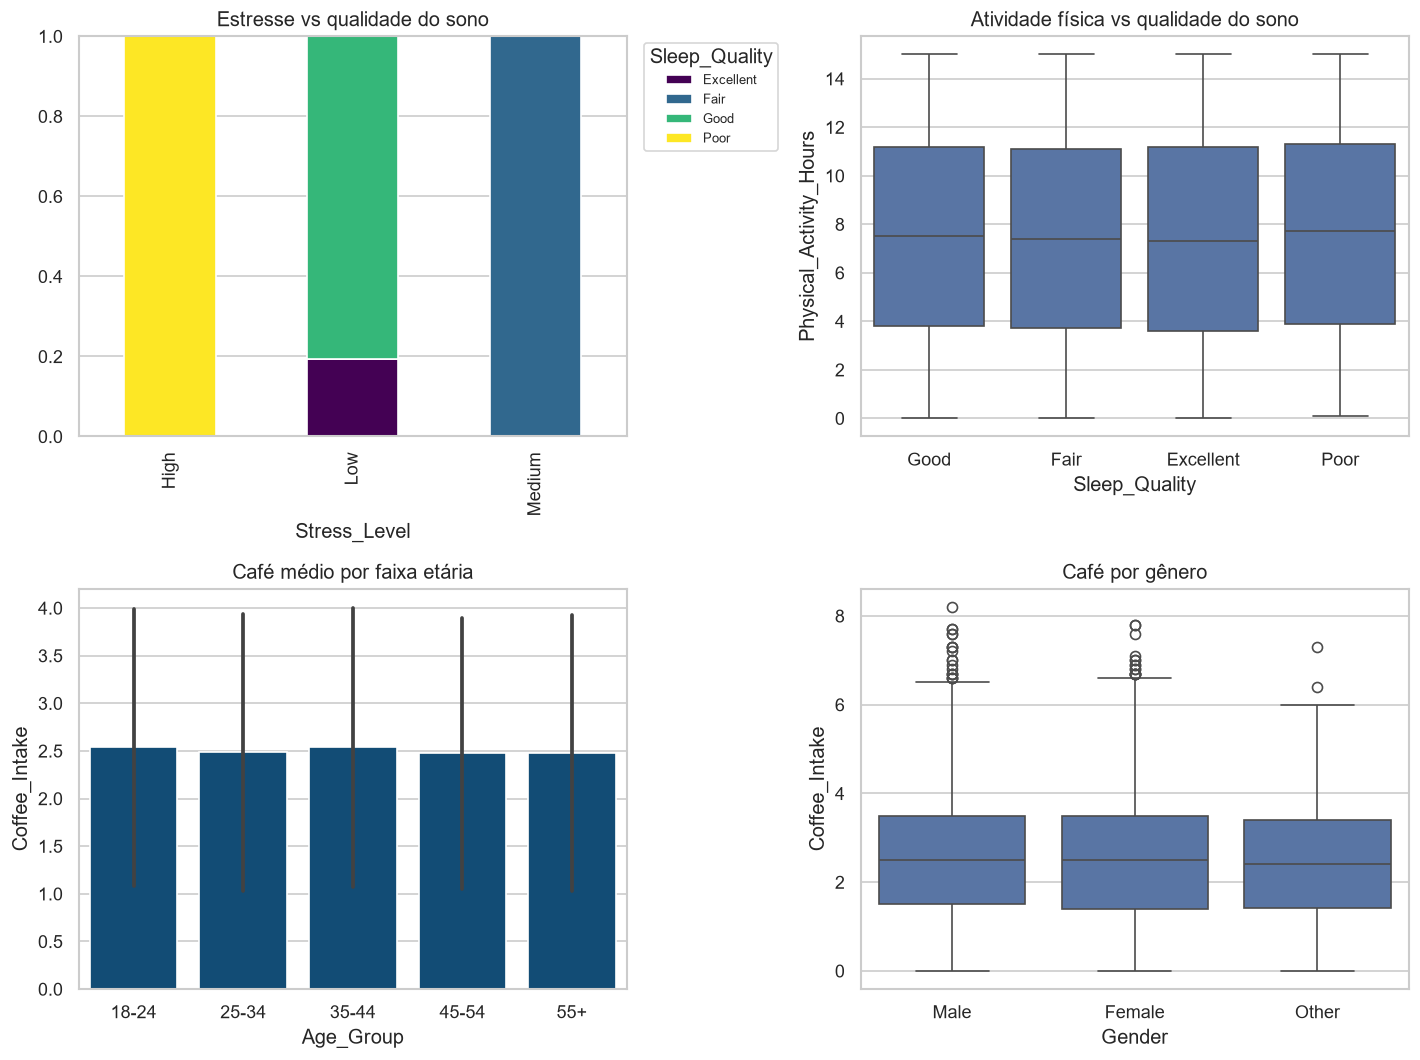

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

tabela = pd.crosstab(df["Stress_Level"], df["Sleep_Quality"], normalize="index")
tabela.plot(kind="bar", stacked=True, ax=axes[0, 0], colormap="viridis")
axes[0, 0].set_title("Estresse vs qualidade do sono")
axes[0, 0].legend(title="Sleep_Quality", bbox_to_anchor=(1.02, 1), fontsize=8)

sns.boxplot(data=df, x="Sleep_Quality", y="Physical_Activity_Hours", ax=axes[0, 1])
axes[0, 1].set_title("Atividade física vs qualidade do sono")

ordem_idade = [o for o in ["18-24", "25-34", "35-44", "45-54", "55+"] if o in df["Age_Group"].unique()]
sns.barplot(data=df, x="Age_Group", y="Coffee_Intake", order=ordem_idade, estimator=np.mean, errorbar="sd", ax=axes[1, 0], color="#014f86")
axes[1, 0].set_title("Café médio por faixa etária")

sns.boxplot(data=df, x="Gender", y="Coffee_Intake", ax=axes[1, 1])
axes[1, 1].set_title("Café por gênero")

plt.tight_layout()
plt.show()


In [12]:
# Exporta todos os gráficos oficiais do projeto para results/graficos/
caminhos = gerar_todas_visualizacoes(df)
print(f"{len(caminhos)} arquivos PNG gerados em {GRAFICOS_DIR}")


15 gráficos salvos em: C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\results\graficos
15 arquivos PNG gerados em C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\results\graficos


### Principais Descobertas

As descobertas abaixo são geradas a partir dos dados reais carregados nesta execução. Elas descrevem **padrões observados**, não relações causais.


In [13]:
# Síntese quantitativa para embasar as descobertas
corr_cafe_sono = df[["Coffee_Intake", "Sleep_Hours"]].corr().iloc[0, 1]
corr_caf_sono = df[["Caffeine_mg", "Sleep_Hours"]].corr().iloc[0, 1]
media_cafe_por_sq = df.groupby("Sleep_Quality")["Coffee_Intake"].mean().sort_values(ascending=False)
media_sono_por_stress = df.groupby("Stress_Level")["Sleep_Hours"].mean().sort_values()
media_cafe_genero = df.groupby("Gender")["Coffee_Intake"].mean()
media_cafe_idade = df.groupby("Age_Group")["Coffee_Intake"].mean().reindex(ordem_idade)

print("Correlação Coffee_Intake x Sleep_Hours:", round(corr_cafe_sono, 3))
print("Correlação Caffeine_mg x Sleep_Hours:", round(corr_caf_sono, 3))
print("\nMédia de café por Sleep_Quality:")
print(media_cafe_por_sq.round(3))
print("\nMédia de Sleep_Hours por Stress_Level:")
print(media_sono_por_stress.round(3))
print("\nMédia de café por Gender:")
print(media_cafe_genero.round(3))
print("\nMédia de café por Age_Group:")
print(media_cafe_idade.round(3))

descobertas = (
    "\n### Principais Descobertas (texto acadêmico)\n"
    "1. A associação linear entre cafeína/café e horas de sono foi medida diretamente nos dados (valores impressos acima).\n"
    "2. Diferenças de consumo médio de café entre classes de Sleep_Quality e faixas etárias podem indicar segmentos úteis para monitoramento populacional.\n"
    "3. A relação entre estresse e horas/qualidade de sono é relevante para dashboards de bem-estar corporativo da Health&Life Analytics.\n"
    "4. Indicadores como BMI, Heart_Rate e Health_Issues devem ser analisados em conjunto com hábitos (fumo/álcool), sem inferir causalidade clínica.\n"
    "5. Como a base é sintética, os padrões servem para demonstração metodológica e prototipagem de produtos analíticos."
)
print(descobertas)


Correlação Coffee_Intake x Sleep_Hours: -0.19
Correlação Caffeine_mg x Sleep_Hours: -0.19

Média de café por Sleep_Quality:
Sleep_Quality
Poor         2.979
Fair         2.764
Good         2.447
Excellent    2.049
Name: Coffee_Intake, dtype: float64

Média de Sleep_Hours por Stress_Level:
Stress_Level
High      4.452
Medium    5.577
Low       7.247
Name: Sleep_Hours, dtype: float64

Média de café por Gender:
Gender
Female    2.498
Male      2.522
Other     2.490
Name: Coffee_Intake, dtype: float64

Média de café por Age_Group:
Age_Group
18-24    2.538
25-34    2.483
35-44    2.539
45-54    2.475
55+      2.477
Name: Coffee_Intake, dtype: float64

### Principais Descobertas (texto acadêmico)
1. A associação linear entre cafeína/café e horas de sono foi medida diretamente nos dados (valores impressos acima).
2. Diferenças de consumo médio de café entre classes de Sleep_Quality e faixas etárias podem indicar segmentos úteis para monitoramento populacional.
3. A relação entre estresse e ho

## 4. Etapa 3 — Machine Learning (classificação de `Sleep_Quality`)

`Sleep_Quality` é tratada como variável **categórica** (classes nominais/ordinais discretas). Não há necessidade de discretização adicional.

Cuidados anti-vazamento:
- `train_test_split` com `random_state=42` e estratificação.
- `Pipeline` + `ColumnTransformer` com scaling/one-hot ajustados apenas no treino.
- Remoção de `ID`.


In [14]:
x, y = preparar_xy(df)
print("Classes alvo:")
print(y.value_counts())
print("\nFeatures:", list(x.columns))
print("Shape X:", x.shape)


Classes alvo:
Sleep_Quality
Good         5637
Fair         2050
Excellent    1352
Poor          961
Name: count, dtype: int64

Features: ['Age', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours', 'Smoking', 'Alcohol_Consumption', 'Caffeine_per_Cup', 'Risk_Habits', 'Gender', 'Country', 'Stress_Level', 'Health_Issues', 'Occupation', 'Age_Group']
Shape X: (10000, 17)


In [15]:
comparacao, detalhes = treinar_e_comparar(df)
display(comparacao)

melhor = comparacao.iloc[0]["modelo"]
print("\nMelhor modelo:", melhor)
print(detalhes[melhor]["classification_report_teste"])
print("Diagnóstico:", detalhes[melhor]["diagnostico"])
print("Modelo salvo em:", RESULTS_DIR / "melhor_modelo.joblib")



===== Random Forest =====
              precision    recall  f1-score   support

   Excellent       0.99      0.94      0.97       270
        Fair       1.00      1.00      1.00       410
        Good       0.99      1.00      0.99      1128
        Poor       1.00      1.00      1.00       192

    accuracy                           0.99      2000
   macro avg       0.99      0.98      0.99      2000
weighted avg       0.99      0.99      0.99      2000

Diagnóstico: Desempenho coerente entre treino e teste.



===== Logistic Regression =====
              precision    recall  f1-score   support

   Excellent       0.97      0.96      0.96       270
        Fair       1.00      1.00      1.00       410
        Good       0.99      0.99      0.99      1128
        Poor       1.00      1.00      1.00       192

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000

Diagnóstico: Desempenho coerente entre treino e teste.

=== Comparação de modelos ===
             modelo  accuracy_treino  accuracy_teste  precision_teste  recall_teste  f1_teste  f1_cv_media  f1_cv_std                               diagnostico
      Random Forest           0.9986           0.991            0.991         0.991    0.9909       0.9917     0.0009 Desempenho coerente entre treino e teste.
Logistic Regression           0.9941           0.990            0.990         0.990    0.9900       0.9916     0.0023 Desempen

,modelo,accuracy_treino,accuracy_teste,precision_teste,recall_teste,f1_teste,f1_cv_media,f1_cv_std,diagnostico
0,Random Forest,0.9986,0.991,0.991,0.991,0.9909,0.9917,0.0009,Desempenho coerente entre treino e teste.
1,Logistic Regression,0.9941,0.990,0.990,0.990,0.9900,0.9916,0.0023,Desempenho coerente entre treino e teste.



Melhor modelo: Random Forest
              precision    recall  f1-score   support

   Excellent       0.99      0.94      0.97       270
        Fair       1.00      1.00      1.00       410
        Good       0.99      1.00      0.99      1128
        Poor       1.00      1.00      1.00       192

    accuracy                           0.99      2000
   macro avg       0.99      0.98      0.99      2000
weighted avg       0.99      0.99      0.99      2000

Diagnóstico: Desempenho coerente entre treino e teste.
Modelo salvo em: C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\results\melhor_modelo.joblib


## 5. Etapa 4 — Exportação dos resultados

Arquivos esperados após a execução:
- `data/processed/coffee_health_processed.csv`
- `results/estatisticas.csv`
- `results/comparacao_modelos.csv`
- `results/melhor_modelo.joblib`
- PNGs em `results/graficos/`


In [16]:
arquivos = [
    DATA_PROCESSED,
    RESULTS_DIR / "estatisticas.csv",
    RESULTS_DIR / "comparacao_modelos.csv",
    RESULTS_DIR / "melhor_modelo.joblib",
]
for arq in arquivos:
    print(("OK" if arq.exists() else "FALTANDO"), "-", arq)

pngs = sorted(GRAFICOS_DIR.glob("*.png"))
print(f"\nGráficos PNG: {len(pngs)}")
for p in pngs:
    print("-", p.name)


OK - C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\data\processed\coffee_health_processed.csv
OK - C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\results\estatisticas.csv
OK - C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\results\comparacao_modelos.csv
OK - C:\Users\tchar\OneDrive\Área de Trabalho\projeto alura\healthlife_analytics\results\melhor_modelo.joblib

Gráficos PNG: 17
- 01_histogramas_numericas.png
- 02_boxplots_principais.png
- 03_barras_sleep_quality.png
- 04_pizza_stress_level.png
- 05_barras_genero.png
- 06_matriz_correlacao.png
- 07_cafe_vs_sleep_quality.png
- 08_cafeina_vs_sleep_hours.png
- 09_cafeina_vs_stress.png
- 10_sleep_hours_vs_quality.png
- 11_stress_vs_sleep_quality.png
- 12_atividade_vs_sleep_quality.png
- 13_idade_vs_cafe.png
- 14_genero_vs_cafe.png
- 15_saude_vs_indicadores.png
- 16_matriz_confusao_random_forest.png
- 17_matriz_confusao_logistic_regression.png


## 6. Etapa 5 — Conclusões e recomendações

### Objetivos e metodologia
O projeto investigou padrões entre hábitos de café/cafeína, sono, estresse e indicadores de saúde com EDA, visualizações e classificação supervisionada de `Sleep_Quality`.

### Principais achados
As métricas e gráficos gerados nesta execução mostram associações descritivas (não causais) entre hábitos e qualidade do sono. O consumo de café/cafeína, o nível de estresse e a atividade física emergem como dimensões úteis para segmentação analítica.

### Resultados dos algoritmos
A tabela `comparacao_modelos.csv` resume acurácia, precisão, recall e F1 em treino/teste, além de validação cruzada. O melhor modelo foi persistido com Joblib para reutilização.

### Limitações
- Dataset sintético: generalização clínica é limitada.
- Possíveis variáveis omitidas (horário do café, transtornos do sono, medicações).
- Correlação e importância preditiva não equivalem a causalidade.

### Recomendações para a Health&Life Analytics
1. Usar os segmentos de sono/estresse para painéis preventivos, com linguagem cuidadosa (associação, não diagnóstico).
2. Priorizar coleta de variáveis temporais (hora do consumo de cafeína) em bases reais futuras.
3. Monitorar overfitting e reavaliar modelos periodicamente com dados novos.
4. Combinar o classificador de `Sleep_Quality` com regras de negócio e validação de especialistas de saúde.

### Melhorias futuras
- Calibração de probabilidades e análise de importância de variáveis (SHAP).
- Testes de modelos boosting (XGBoost/LightGBM) e balanceamento de classes, se necessário.
- Validação externa em dados reais anonimizados.
